# *Density Analysis Tool*

Kernel Estimation, Ripleys K function, Nearest Neighbors

In [3]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../")
from analysis.density_methods import SpineDensity as sd

%load_ext autoreload
%autoreload 2

### Import Data
- Change the `data_dir` variable to specify the local directory where annotated spine data files are stored. 
- These files should contain the spine location information in **CSV** format
- After specifying the filepath and running the cell, the identified file names will be printed. Review that these are the correct files and there are no extra files in the directory.

In [48]:
# change filepath for the data directory to be analyzed
data_dir = r"C:\Users\brogab\Documents\spines\data\comp_brian\CSV_spines"
# ------------------------------------------------------------------------

# inspect the files to load before loading them
spine_files = os.listdir(data_dir)
print('Identified files:')
for file in os.listdir(data_dir):
    print(f'    {file}')

Identified files:
    Lightning 001Oblique1_Lng_spines.csv
    Lightning 002_MainApical1_Lng_spines.csv
    Lightning 003_Tuft1_Lng_spines.csv
    Lightning 004_Tuft1_Lng_spines.csv


**After confirming that the directory is correct, import the files to a DataFrame by running the following cell**

In [53]:
# import the files, recording the origin name
spine_data = None
for file in os.listdir(data_dir):
    if file.endswith(".csv"):
        temp = pd.read_csv(os.path.join(data_dir, file))
        temp['origin'] = file
    
        if spine_data is None:
            spine_data = temp
        else:
            spine_data = pd.concat([spine_data, temp])
        del temp
n_files = spine_data['origin'].unique().shape[0]
print(f'Imported data from {n_files} source files')
print(f'Spine DataFrame has {spine_data.shape[0]} rows and {spine_data.shape[1]} columns')
print('\nFirst 10 rows of the imported data:')
spine_data.head(10)

Imported data from 4 source files
Spine DataFrame has 282 rows and 22 columns

First 10 rows of the imported data:


,ID,SECTION-NUMBER,SECTION-LENGTH,BRANCH-ORDER,RAYBURST-VOLUME,NON-ATTACH-SA,X,Y,Z,HEAD-DIAMETER,...,TYPE,AUTO,XYPLANE-ANGLE,SWC-NODE-ID,SWC-NODE-OFFSET,ATTACH-X,ATTACH-Y,ATTACH-Z,SOMA-DISTANCE,origin
0,20,0,41.438396,NaN,0.864466,6.135283,34.848038,20.175327,5.475138,0.580760,...,mushroom,yes,68.623043,97,0.000000,34.206104,20.469563,7.279165,36.664646,Lightning 001Oblique1_Lng_spines.csv
1,26,0,41.438396,NaN,0.032299,0.553776,30.190857,20.253418,4.219728,0.264558,...,thin,yes,85.433614,85,0.000000,30.216919,20.439192,6.568526,31.517948,Lightning 001Oblique1_Lng_spines.csv
2,28,0,41.438396,NaN,0.199526,1.924669,1.577570,12.021452,2.836537,0.430510,...,mushroom,yes,4.259670,4,0.000000,1.661347,14.010247,2.984799,1.243300,Lightning 001Oblique1_Lng_spines.csv
3,30,0,41.438396,NaN,0.672676,4.291018,11.842226,13.409301,3.331609,0.768083,...,mushroom,yes,41.430899,30,0.000000,11.851035,14.570062,4.356100,11.871390,Lightning 001Oblique1_Lng_spines.csv
4,31,0,41.438396,NaN,0.405092,3.073693,31.240519,21.188101,5.215016,0.644852,...,mushroom,yes,51.830135,89,0.000000,30.678320,20.274363,6.579829,33.335506,Lightning 001Oblique1_Lng_spines.csv
5,33,0,41.438396,NaN,0.665628,4.292342,3.420799,15.794722,3.248447,0.882787,...,mushroom,yes,-3.087550,9,0.000000,3.980199,14.435533,3.169166,3.606890,Lightning 001Oblique1_Lng_spines.csv
6,34,0,41.438396,NaN,0.194305,2.004291,16.977730,19.708521,4.322408,0.477194,...,mushroom,yes,0.854152,52,0.020302,17.520660,18.101688,4.347694,19.178658,Lightning 001Oblique1_Lng_spines.csv
7,38,0,41.438396,NaN,0.015860,0.353215,25.188562,22.102594,5.667088,0.154789,...,thin,yes,4.459167,76,0.414875,25.480772,20.242477,5.813927,27.742182,Lightning 001Oblique1_Lng_spines.csv
8,39,0,41.438396,NaN,0.394366,3.263946,14.636175,14.101749,4.977990,0.647608,...,mushroom,yes,-8.579241,36,0.000000,14.337535,15.756664,4.724288,14.018100,Lightning 001Oblique1_Lng_spines.csv
9,40,0,41.438396,NaN,0.182935,1.897535,6.877020,13.871788,4.691661,0.549248,...,mushroom,yes,-31.586644,16,0.000000,7.941986,14.818292,3.815584,6.401284,Lightning 001Oblique1_Lng_spines.csv


### Inspect Spine Locations
- Run the following cell to create a plot array showing the spine locations for each imported dataset
- Within each plot, the spines are seperated by branch

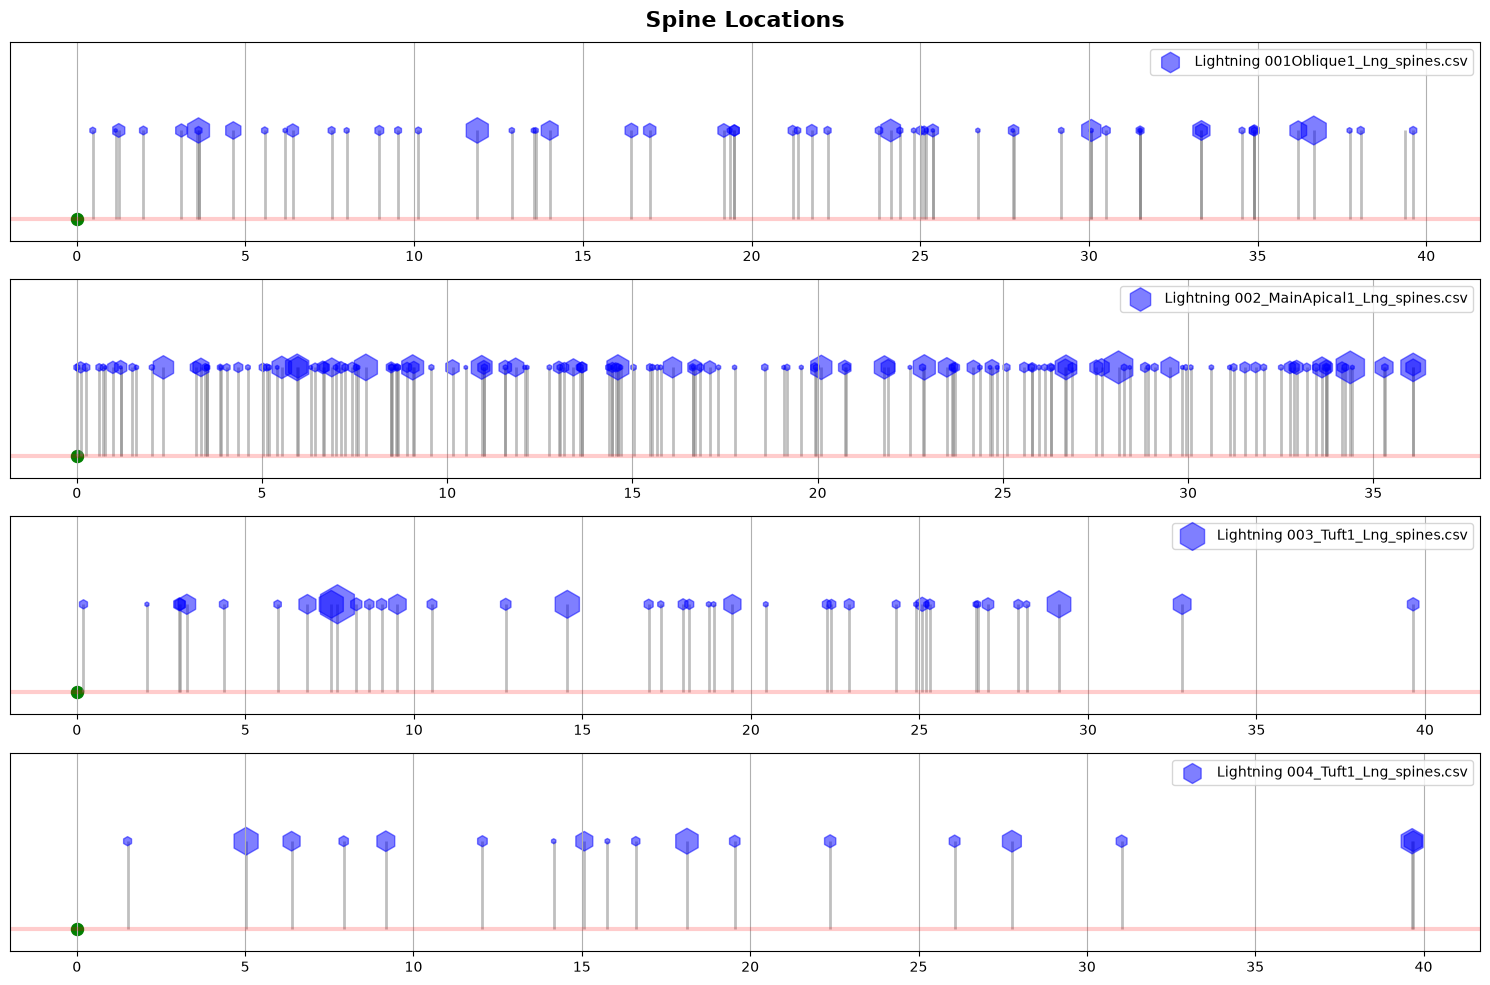

In [8]:
# visulaize spines for each imported branch
fig, axes = plt.subplots(n_files, 1, sharex=False, figsize=(15,2.5*n_files))
axes = np.atleast_1d(axes)

fig.suptitle('Spine Locations', fontsize=16, fontweight='bold')
for idx, origin in enumerate(spine_data['origin'].unique().tolist()):
    spines_i = spine_data[spine_data["origin"] == origin].loc[:, "SOMA-DISTANCE"].to_numpy()
    size_i = spine_data[spine_data["origin"] == origin].loc[:, "RAYBURST-VOLUME"].to_numpy() * 500
    
    axes[idx].axhline(y=0, color='r', linestyle='-', linewidth=3.0, alpha=0.2)
    axes[idx].scatter(0, 0, marker='o', color='g', s=75)
    axes[idx].vlines(x=spines_i, ymin=0, ymax=1, color='gray', linestyle='-', linewidth=2.0, alpha=0.5, zorder=1)
    axes[idx].scatter(spines_i, np.ones(spines_i.shape), color='blue', marker = 'h', s = size_i, label=origin, alpha = 0.5)
    axes[idx].legend(loc="upper right")
    axes[idx].set_ylim(-0.25, 2)
    axes[idx].set_yticks([])
    axes[idx].grid()
plt.tight_layout()
plt.show()

In [9]:
# visualize nearest neighbors comparison with a seaborn boxplot

nn_dfs = []
for idx, origin in enumerate(spine_data['origin'].unique().tolist()):
    spines_i = spine_data.loc[spine_data['origin'] == origin, 'SOMA-DISTANCE'].to_numpy()
    avg_nn_spines, dist_arr = sd.avg_nn_1D(spines_i)
    df_origin = pd.DataFrame({
            'origin': origin,
            'nn_dist': dist_arr,
            'avg_nn': avg_nn_spines  # Optional: repeats the group mean on each row if needed
    })
    nn_dfs.append(df_origin)
nn_df = pd.concat(nn_dfs, ignore_index=True)

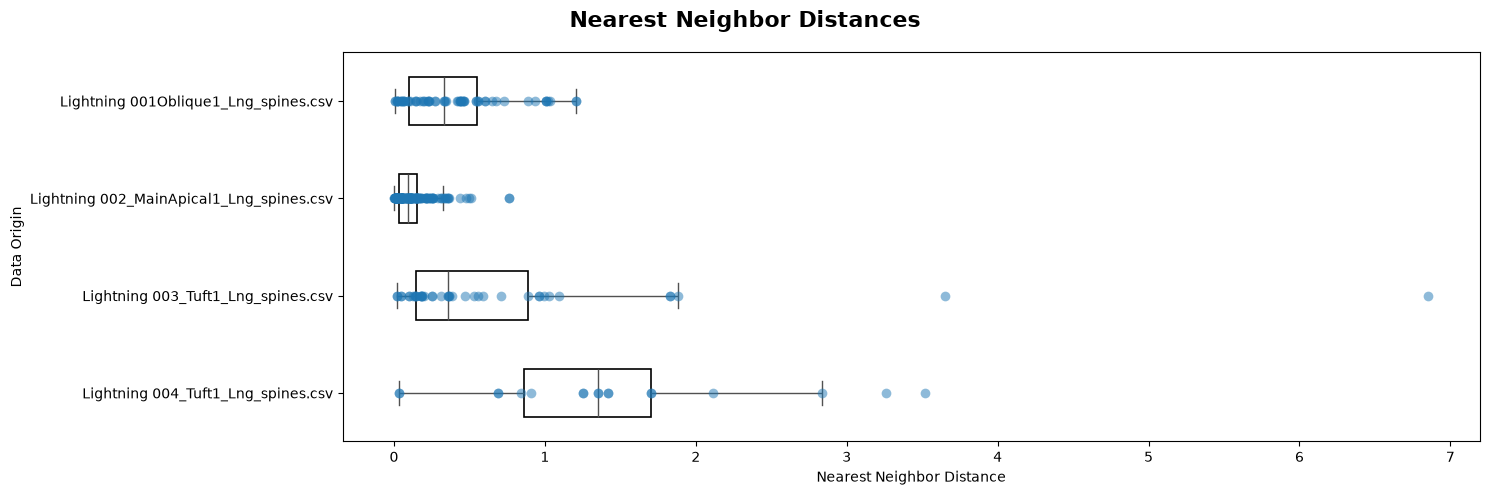

In [10]:
plt.figure(figsize=(15,5))
plt.suptitle("Nearest Neighbor Distances", fontsize=16, fontweight='bold')
sns.stripplot(data=nn_df, x='nn_dist', y='origin', marker = 'o', jitter=False, alpha=0.5, size=7, orient='h')
sns.boxplot(data=nn_df, x='nn_dist', y='origin', width=0.5, showfliers=False, boxprops=dict(facecolor='none', edgecolor='black', linewidth=1.2))


plt.ylabel("Data Origin")
plt.xlabel("Nearest Neighbor Distance")
plt.tight_layout()
plt.show()

### DBSCAN

In [11]:
# DBSCAN clustering based from specified params
eps = .5
min_pts = 2

scans = {}

for idx, origin in enumerate(spine_data['origin'].unique().tolist()):
    spines_i = spine_data.loc[spine_data['origin'] == origin, 'SOMA-DISTANCE'].to_numpy()
    dbscan = sd.dbscan(spines_i, eps, min_pts)

    # shift non-negative clusters
    dbscan[dbscan > -1] += 1
    scans[f'{origin}_clust'] = dbscan
    scans[f'{origin}_c2p_ratio'] = np.unique(dbscan).shape[0] / spines_i.shape[0]

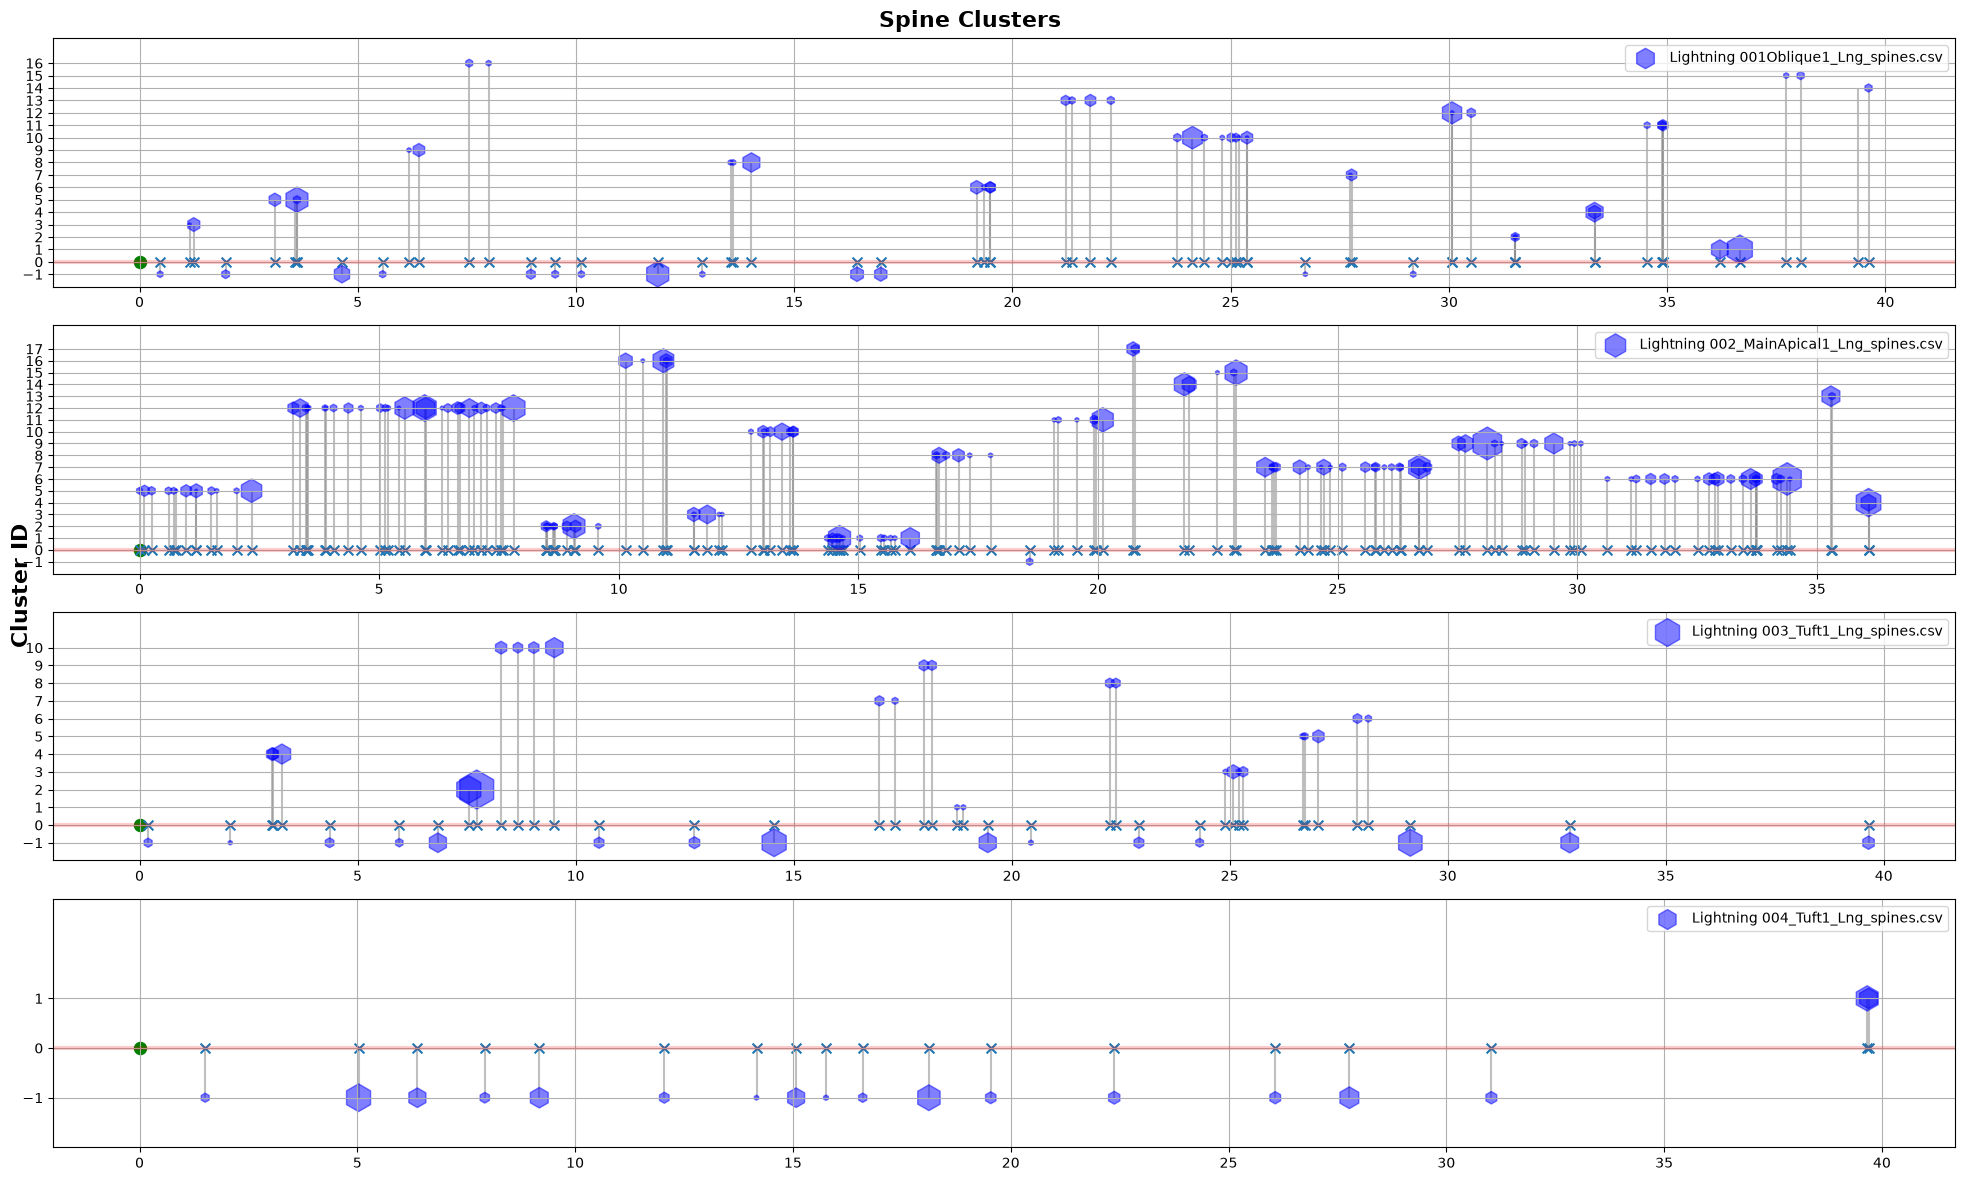

In [12]:
# visulaize spine clusters for each imported branch
fig, axes = plt.subplots(n_files, 1, sharex=False, figsize=(20,3*n_files))
axes = np.atleast_1d(axes)
fig.suptitle('Spine Clusters', fontsize=16, fontweight='bold')
fig.supylabel("Cluster ID", fontsize=16, fontweight='bold', rotation=90, va='center')
for idx, origin in enumerate(spine_data['origin'].unique().tolist()):
    spines_i = spine_data[spine_data["origin"] == origin].loc[:, "SOMA-DISTANCE"].to_numpy()
    size_i = spine_data[spine_data["origin"] == origin].loc[:, "RAYBURST-VOLUME"].to_numpy() * 500
    
    axes[idx].axhline(y=0, color='r', linestyle='-', linewidth=3.0, alpha=0.2)
    axes[idx].scatter(0, 0, marker='o', color='g', s=75)

    axes[idx].vlines(x=spines_i, ymin=0, ymax=scans[f'{origin}_clust'], color='gray', linestyle='-', linewidth=1.5, alpha=0.5, zorder=1)
    
    axes[idx].scatter(spines_i, np.full(spines_i.shape, 0.0), marker = 'x', s = 50)
    axes[idx].scatter(spines_i, scans[f'{origin}_clust'], c='blue', marker = 'h', s = size_i, label=origin, alpha = 0.5)
    
    y_ticks = np.arange(-1, np.max(scans[f'{origin}_clust'])+1)
    axes[idx].set_ylim(-2, np.max(y_ticks)+2)
    axes[idx].set_yticks(y_ticks)
    
    axes[idx].legend(loc="upper right")
    axes[idx].grid()
    
plt.tight_layout()
plt.show()

### RIPLEY'S KFUNC

In [37]:
# perform Ripley's K-Function analysis
# set radii
radius_lw_bound = 1e-5
radius_up_bound = 25
radius_density = 100

rad_arr = np.linspace(radius_lw_bound, radius_up_bound, radius_density)
csr = 2.0 * rad_arr

rip_dict = {}
for idx, origin in enumerate(spine_data['origin'].unique().tolist()):
    spine_i = spine_data[spine_data['origin'] == origin].loc[:, "SOMA-DISTANCE"].to_numpy()
    L = spine_data[spine_data['origin'] == origin].loc[0, "SECTION-LENGTH"]
    rip_arr = np.array([sd.ripley_kfunc_1D(spine_i, L, r) for r in rad_arr])
    rip_dict[f'{origin}_rip'] = rip_arr
    rip_dict[f'{origin}_dif'] = rip_arr - csr

rip_df = pd.DataFrame(rip_dict)

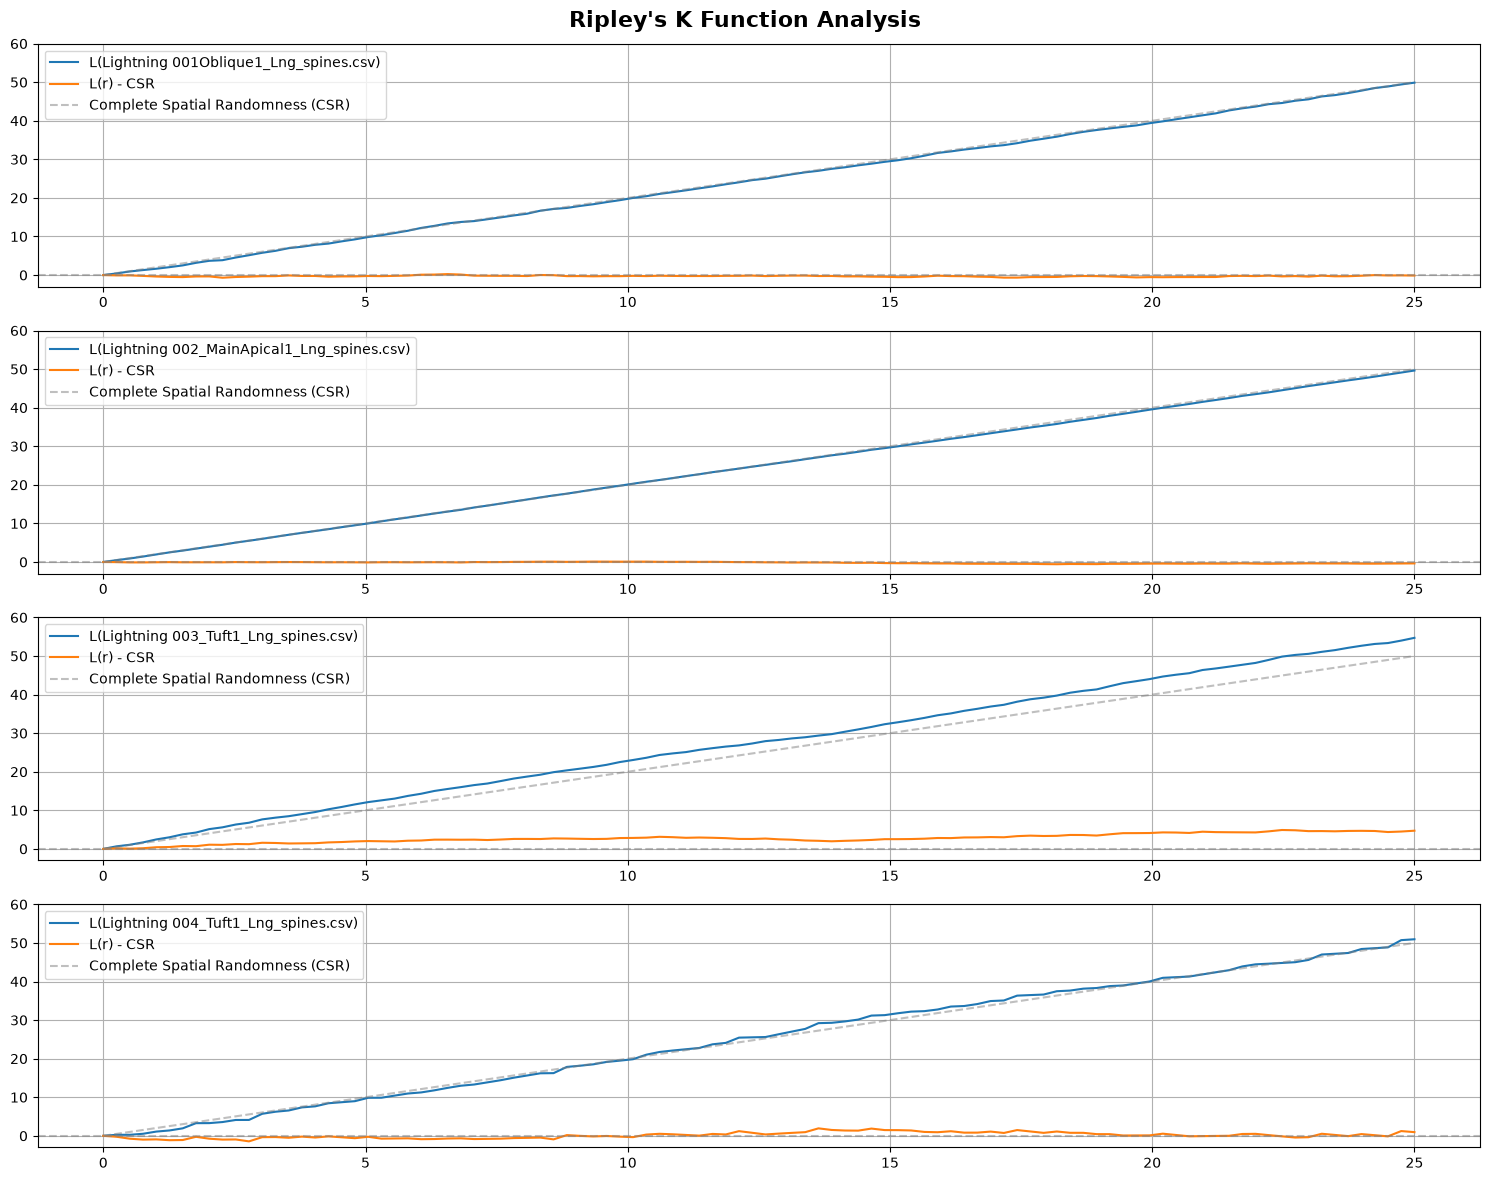

In [39]:
# visulaize spines for each imported branch
fig, axes = plt.subplots(n_files, 1, sharex=False, figsize=(15,3*n_files))
axes = np.atleast_1d(axes)
fig.suptitle("Ripley's K Function Analysis", fontsize=16, fontweight='bold')
for idx, origin in enumerate(spine_data['origin'].unique().tolist()):
    spines_i = spine_data[spine_data["origin"] == origin].loc[:, "SOMA-DISTANCE"].to_numpy()
    
    # plot Ripley's
    axes[idx].plot(rad_arr, rip_dict[f'{origin}_rip'], label=f'L({origin})')
    axes[idx].plot(rad_arr, rip_dict[f'{origin}_rip'] - csr, label='L(r) - CSR')
    
    # plot complete spatial randomness
    axes[idx].plot(rad_arr, csr, label='Complete Spatial Randomness (CSR)', linestyle='--', color='gray', alpha=0.5)
    axes[idx].axhline(y=0.0, linestyle='--', color='gray', alpha=0.5)
    
    axes[idx].legend(loc="upper left")
    axes[idx].set_ylim(-3, 60)
    axes[idx].grid()
    
plt.tight_layout()
plt.show()